## About the Project
Hotel Revenue Leakage Audit is an Exploratory Data Analysis (EDA) project focused on understanding booking patterns, cancellation behavior, and potential revenue leakages in the hospitality industry. Using the Hotel Booking Demand dataset from Kaggle, the analysis examines booking characteristics, customer segments, deposit policies, lead time, distribution channels, and room allocation changes. The project also quantifies the estimated revenue lost due to historical booking cancellations and identifies high-risk booking patterns.

## Problem Statement
Hotels face significant revenue uncertainty due to booking cancellations and inefficient distribution channels. Since hotel rooms are perishable inventory, a cancelled booking can result in a lost revenue opportunity if the room remains unoccupied. This project aims to identify the major factors associated with booking cancellations, detect high-risk booking profiles, analyze channel-level revenue patterns, and calculate the estimated historical revenue exposure caused by cancellations. The findings can help hotel management improve cancellation policies, booking strategies, and revenue management decisions.

In [1]:
# importing major libraries
# Data Wrangling / Data Manipulation

import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("hotel_bookings.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df.shape

(119390, 32)

In [4]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [5]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

### Data Card: Hotel Booking Demand Dataset

This dataset contains hotel booking information, including **booking details, guest characteristics, stay duration, room allocation, cancellation status, and revenue-related information**. Each row represents **one hotel booking**, and each column describes a specific attribute of the booking or guest.

| Column                             | Data Type        | Description                                                        |
| ---------------------------------- | ---------------- | ------------------------------------------------------------------ |
| **hotel**                          | Categorical      | Type of hotel — City Hotel or Resort Hotel                         |
| **is_canceled**                    | Numeric / Binary | Indicates whether the booking was canceled (1) or not (0)          |
| **lead_time**                      | Numeric          | Number of days between booking and arrival                         |
| **arrival_date_year**              | Numeric          | Year of the guest's arrival                                        |
| **arrival_date_month**             | Categorical      | Month of the guest's arrival                                       |
| **arrival_date_week_number**       | Numeric          | Week number of the arrival                                         |
| **arrival_date_day_of_month**      | Numeric          | Day of the month of arrival                                        |
| **stays_in_weekend_nights**        | Numeric          | Number of weekend nights booked                                    |
| **stays_in_week_nights**           | Numeric          | Number of weekday nights booked                                    |
| **adults**                         | Numeric          | Number of adults in the booking                                    |
| **children**                       | Numeric          | Number of children in the booking                                  |
| **babies**                         | Numeric          | Number of babies in the booking                                    |
| **meal**                           | Categorical      | Meal plan selected by the guest                                    |
| **country**                        | Categorical      | Country of origin of the guest                                     |
| **market_segment**                 | Categorical      | Market segment through which the booking was made                  |
| **distribution_channel**           | Categorical      | Channel used to distribute or generate the booking                 |
| **is_repeated_guest**              | Numeric / Binary | Indicates whether the guest is a returning guest (1 = Yes, 0 = No) |
| **previous_cancellations**         | Numeric          | Number of previous bookings canceled by the guest                  |
| **previous_bookings_not_canceled** | Numeric          | Number of previous bookings that were not canceled                 |
| **reserved_room_type**             | Categorical      | Room type originally reserved                                      |
| **assigned_room_type**             | Categorical      | Room type actually assigned                                        |
| **booking_changes**                | Numeric          | Number of changes made to the booking                              |
| **deposit_type**                   | Categorical      | Type of deposit required for the booking                           |
| **agent**                          | Numeric          | ID of the travel agent associated with the booking                 |
| **company**                        | Numeric          | ID of the company associated with the booking                      |
| **days_in_waiting_list**           | Numeric          | Number of days the booking remained on the waiting list            |
| **customer_type**                  | Categorical      | Type of customer making the booking                                |
| **adr**                            | Numeric          | Average Daily Rate charged for the booking                         |
| **required_car_parking_spaces**    | Numeric          | Number of car parking spaces required                              |
| **total_of_special_requests**      | Numeric          | Total number of special requests made by the guest                 |
| **reservation_status**             | Categorical      | Final status of the reservation                                    |
| **reservation_status_date**        | Date             | Date when the reservation status was last updated                  |

### Target Variable

**`is_canceled`** → Main target variable

* `0` = Not canceled
* `1` = Canceled



In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

### Data Observation

* Dataset contains **119,390 rows and 32 columns**.
* There are **16 integer columns**, **4 float columns**, and **12 string/object columns**.
* Most columns have complete data, but a few columns contain missing values.
* `is_canceled` is an **integer binary variable (0/1)**.
* `children` and `agent/company` are numeric columns stored as `float64`, mainly because of missing values.
* Date information is currently split across `arrival_date_year`, `arrival_date_month`, and `arrival_date_day_of_month`.

### Potential Issues

1. **Missing values**

   * `children`: 4 missing values
   * `country`: 488 missing values
   * `agent` and `company`: many missing values
   * These need to be investigated before analysis where those columns are used.

2. **Date structure**

   * Arrival date is split into three separate columns.
   * It should be combined into a single `datetime` column for chronological analysis.

3. **Guest-count anomaly**

   * `adults`, `children`, and `babies` can potentially all be `0`.
   * These records need to be checked as **Ghost Guest Records** according to the assignment.

4. **Financial anomaly**

   * `adr` may contain **0 or negative values**.
   * Since ADR represents the daily room rate, such records need investigation, especially for bookings where `is_canceled = 0`.

5. **Categorical columns**

   * Columns such as `hotel`, `meal`, `market_segment`, `deposit_type`, and `customer_type` are categorical and need category-wise analysis rather than numerical aggregation.

**Important:** Abhi in issues ko fix/delete mat karo. Assignment ke according pehle **identify → quantify → investigate → then clean if required**.


In [7]:
df["children"] = df["children"].fillna(0).astype(int)

In [8]:
df.duplicated().sum()

np.int64(31994)

# Observation
31994 exact duplicate rows were identified. Since the dataset does not contain a unique booking ID, these records cannot be confidently classified as erroneous duplicates. Therefore, they are retained for further analysis.

In [9]:
df['hotel'].value_counts()

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

In [10]:
df["deposit_type"].value_counts()

deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64

In [11]:
df["reservation_status"].value_counts()

reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64

In [12]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103886,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398555,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000



### Data Observations

1. Dataset mein **119,390 observations** hain, aur most numeric columns mein complete records available hain.
2. `is_canceled` ka mean **0.3704** hai, indicating approximately **37% bookings were canceled**.
3. `lead_time` ka mean **104 days** hai, while maximum **737 days** hai, showing a wide variation in booking lead time.
4. Dataset mein arrival years **2015–2017** ke beech hain.
5. Average stay approximately **3.43 nights** hai (`0.93` weekend + `2.50` weekday nights).
6. Average number of adults approximately **1.86**, while children and babies ka average relatively low hai.
7. `adr` ka mean approximately **101.83** hai, with values ranging from **-6.38 to 5400**.
8. `required_car_parking_spaces` ka mean **0.06** hai, indicating most bookings did not require parking.
9. `total_of_special_requests` ka mean **0.57** hai, with a maximum of **5** requests.
10. `is_repeated_guest` ka mean **0.032** hai, indicating repeat-guest bookings are relatively uncommon.

### ⚠️ Important Potential Issues

* **ADR minimum = -6.38** → negative ADR is a clear financial anomaly and directly relevant to the **Financial Anomaly Extraction** step.
* **ADR = 0** records bhi investigate karne hain, especially where `is_canceled = 0`.
* `lead_time` maximum **737 days** hai → long-lead bookings exist and are relevant for **Lead Time Risk Cut-off**.
* `adults`, `children`, and `babies` mein minimum **0** hai → possible **Ghost Guest Records** identify karne hain.
* `agent` aur `company` ka count lower hai (**103,050** and **6,797**) → these columns contain substantial missing values.
* `previous_cancellations` maximum **26** and `previous_bookings_not_canceled` maximum **72** hai → customer booking history has considerable variation.

**Sabse important:** `adr = -6.38` ko abhi remove mat karna. Assignment specifically tumhe **zero aur negative ADR** investigate karne ko bol raha hai.


# Phase 1: Data Integrity & Inconsistency Sanity Audit

In [13]:
# The Ghost Guest Audit 

df["total_guests"] = df["adults"] + df["children"] + df['babies']

In [14]:
Ghost_records = df[df["total_guests"] == 0]
Ghost_count = len(Ghost_records)
Ghost_count



180

In [15]:
plt.figure(figsize=(10,6))

sns.countplot(df["is_canceled"])

<Axes: ylabel='count'>

Error in callback <function flush_figures at 0x0000018020CBECF0> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

In [16]:
ghost_percentage = (Ghost_count / len(df))*100
ghost_percentage

0.1507663958455482

In [17]:
# 6 Statistical baseline
print("Ghost_count" , Ghost_count)
print("ghost_percentage" ,ghost_percentage)


Ghost_count 180
ghost_percentage 0.1507663958455482


In [18]:
# Financial Anomaly Extraction 
financial_anomalies = df[(df["is_canceled"] == 0) & (df["adr"] <=0)]
len(financial_anomalies)



1747

In [19]:
adr_zero = financial_anomalies[financial_anomalies["adr"] == 0]
len(adr_zero)

1746

In [20]:
negative_adr = financial_anomalies[financial_anomalies["adr"] < 0]
len(negative_adr)

1

In [21]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'total_guests'],
      dtype='str')

In [22]:
# segment observations
financial_anomalies["hotel"].value_counts()



hotel
City Hotel      1079
Resort Hotel     668
Name: count, dtype: int64

In [23]:
financial_anomalies["distribution_channel"].value_counts()

distribution_channel
TA/TO        870
Direct       707
Corporate    166
GDS            4
Name: count, dtype: int64

In [24]:
financial_anomalies["market_segment"].value_counts()

market_segment
Complementary    588
Online TA        347
Offline TA/TO    292
Groups           229
Direct           209
Corporate         77
Aviation           5
Name: count, dtype: int64

In [25]:
financial_anomalies[
    ["hotel", "adr", "market_segment",
     "distribution_channel", "deposit_type",
     "stays_in_week_nights", "stays_in_weekend_nights"]
].head(20)

,hotel,adr,market_segment,distribution_channel,deposit_type,stays_in_week_nights,stays_in_weekend_nights
0,Resort Hotel,0.0,Direct,Direct,No Deposit,0,0
1,Resort Hotel,0.0,Direct,Direct,No Deposit,0,0
125,Resort Hotel,0.0,Complementary,Direct,No Deposit,1,0
167,Resort Hotel,0.0,Online TA,TA/TO,No Deposit,0,0
168,Resort Hotel,0.0,Direct,Direct,No Deposit,0,0
196,Resort Hotel,0.0,Direct,Direct,No Deposit,0,0
197,Resort Hotel,0.0,Online TA,TA/TO,No Deposit,0,0
428,Resort Hotel,0.0,Groups,Direct,No Deposit,2,0
459,Resort Hotel,0.0,Online TA,TA/TO,No Deposit,0,0
568,Resort Hotel,0.0,Offline TA/TO,TA/TO,No Deposit,0,0


In [26]:
# Temporal Feature Aggregation

df["arrival_date"] = pd.to_datetime(df["arrival_date_year"].astype(str)+"-"+ df["arrival_date_month"]+"-"+ df["arrival_date_day_of_month"].astype(str))

In [27]:
df[
    [
        "arrival_date_year",
        "arrival_date_month",
        "arrival_date_day_of_month",
        "arrival_date"
    ]
].head()

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01


In [28]:
df['arrival_date'].dtype

dtype('<M8[us]')

In [29]:
df["arrival_date"].min()

Timestamp('2015-07-01 00:00:00')

In [30]:
df["arrival_date"].max()

Timestamp('2017-08-31 00:00:00')

# Phase 2: Bivariate Leakage Drivers (Cancellation Profiling)

In [31]:
# Deposit Policy Efficacy

df["deposit_type"].value_counts()

deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64

In [32]:
deposit_analysis = df.groupby("deposit_type")["is_canceled"].agg(
    total_booking ="count",
    cancellation_rate ="mean"
)

deposit_analysis["cancellation_rate"]*=100
deposit_analysis

,total_booking,cancellation_rate
deposit_type,,
No Deposit,104641,28.377022
Non Refund,14587,99.362446
Refundable,162,22.222222


              total_booking  cancellation_rate
deposit_type                                  
No Deposit           104641          28.377022
Non Refund            14587          99.362446
Refundable              162          22.222222


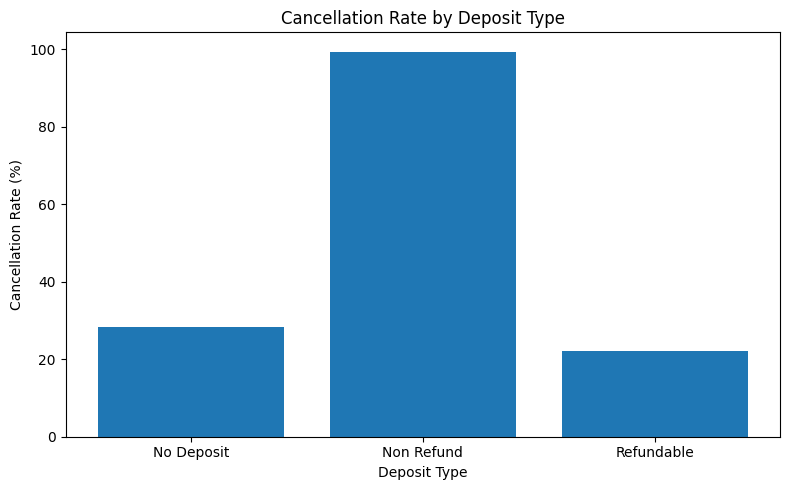

In [33]:
print(deposit_analysis)
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    deposit_analysis.index,
    deposit_analysis["cancellation_rate"]
)

plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Deposit Type")

plt.tight_layout()
plt.show()

Executive Consulting Insight

Non-refundable bookings recorded the highest cancellation rate at 99.36%, substantially above No Deposit (28.38%) and Refundable (22.22%) bookings. Therefore, in this dataset, the non-refundable category does not demonstrate the expected cancellation-dampening effect and requires further investigation.

In [34]:
# Lead Time Risk Cut-off
lead_time_analysis = (
    df.groupby("lead_time")["is_canceled"]
    .agg(
        total_bookings="count",
        cancellation_rate="mean"
    )
)

lead_time_analysis["cancellation_rate"] *= 100

In [35]:
lead_time_analysis["rate_change"] = (
    lead_time_analysis["cancellation_rate"].diff()
)

In [36]:
lead_time_analysis[
    lead_time_analysis["total_bookings"] >= 100
].sort_values(
    "rate_change",
    ascending=False
).head(15)

,total_bookings,cancellation_rate,rate_change
lead_time,,,
258,145,71.034483,47.549634
288,110,64.545455,42.486631
272,143,60.839161,33.366633
302,147,89.115646,33.326173
323,148,85.810811,28.810811
226,190,53.684211,27.477314
267,124,86.290323,27.079796
238,126,69.841270,26.091270
297,104,57.692308,26.025641


In [37]:
lead_time_analysis["rolling_rate"] = (
    lead_time_analysis["cancellation_rate"]
    .rolling(window=15, min_periods=5)
    .mean()
)

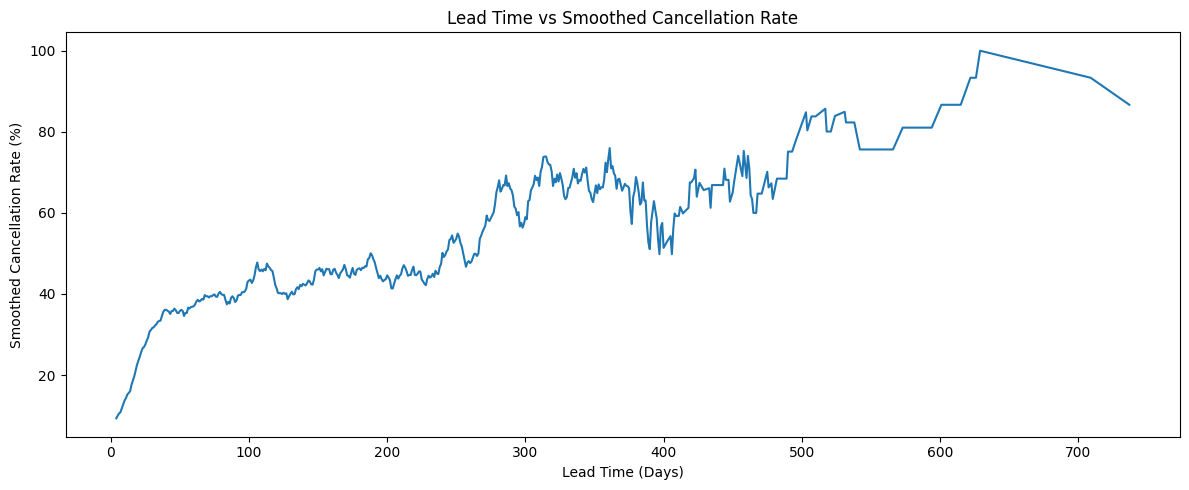

In [38]:
plt.figure(figsize=(12,5))

plt.plot(
    lead_time_analysis.index,
    lead_time_analysis["rolling_rate"]
)

plt.xlabel("Lead Time (Days)")
plt.ylabel("Smoothed Cancellation Rate (%)")
plt.title("Lead Time vs Smoothed Cancellation Rate")

plt.tight_layout()
plt.show()

In [39]:
threshold_candidates = lead_time_analysis[
    (lead_time_analysis["rolling_rate"] >= 50) &
    (lead_time_analysis["total_bookings"] >= 100)
]

threshold_candidates.head(20)

,total_bookings,cancellation_rate,rate_change,rolling_rate
lead_time,,,,
188,251,64.143426,16.815182,50.043025
240,145,66.896552,13.649798,50.139443
243,104,55.769231,4.825835,50.501353
244,149,71.140940,15.371709,51.007971
245,200,79.000000,7.859060,53.311674
247,206,54.854369,7.179950,54.437131
251,126,50.000000,-9.340659,54.896986
253,105,46.666667,14.234234,52.597508
267,124,86.290323,27.079796,53.574415


Eata-driven risk threshold: Around 188 days of lead time, the smoothed cancellation rate crosses the 50% level, indicating a transition into a higher-risk booking zone. The risk becomes more pronounced beyond approximately 270 days, where the smoothed cancellation rate remains substantially elevated.

In [40]:
threshold = 188

before_threshold = df[df["lead_time"] < threshold]
at_or_above_threshold = df[df["lead_time"] >= threshold]

comparison = pd.DataFrame({
    "Booking Volume": [
        len(before_threshold),
        len(at_or_above_threshold)
    ],
    "Cancellation Rate (%)": [
        before_threshold["is_canceled"].mean() * 100,
        at_or_above_threshold["is_canceled"].mean() * 100
    ]
}, index=[
    f"Below {threshold} days",
    f"{threshold}+ days"
])

comparison

,Booking Volume,Cancellation Rate (%)
Below 188 days,96231,32.112313
188+ days,23159,57.524073


Bookings with a lead time of 188 days or more show substantially higher cancellation risk, with a 57.52% cancellation rate compared with 32.11% for bookings below 188 days. This identifies 188 days as a data-driven operational risk cut-off in this dataset.

In [41]:
# Customer Segment Volatility
#Cancellation rate
customer_cancellation = (
    df.groupby("customer_type")["is_canceled"].mean() * 100
)

customer_cancellation.sort_values(ascending=False)

customer_type
Transient          40.746320
Contract           30.961727
Transient-Party    25.429868
Group              10.225303
Name: is_canceled, dtype: float64

In [42]:
# Normalized status table
customer_status = pd.crosstab(
    df["customer_type"],
    df["is_canceled"],
    normalize="index"
) * 100

customer_status

is_canceled,0,1
customer_type,,
Contract,69.038273,30.961727
Group,89.774697,10.225303
Transient,59.253680,40.746320
Transient-Party,74.570132,25.429868


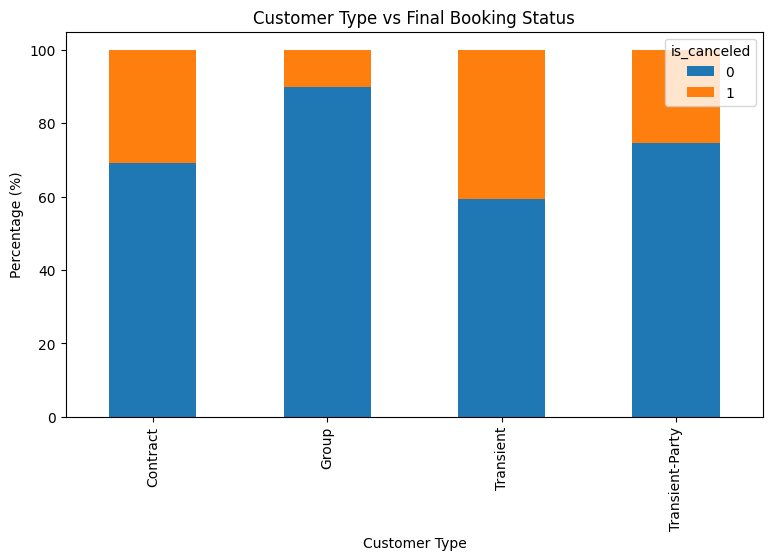

In [43]:
customer_status.plot(
    kind="bar",
    stacked=True,
    figsize=(9,5)
)

plt.xlabel("Customer Type")
plt.ylabel("Percentage (%)")
plt.title("Customer Type vs Final Booking Status")

plt.show()

PHASE 3 — Multivariate Channel & Room Analysis

In [44]:
channel_bookings = (
    df["distribution_channel"]
    .value_counts()
)
channel_bookings

distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64

In [45]:
#Distribution Channel Margin Grid
# Average ADR
channel_adr = (
    df.groupby("distribution_channel")["adr"].mean()
)

In [46]:
#Cancellation rate
channel_cancellation = (
    df.groupby("distribution_channel")["is_canceled"].mean() * 100
)

In [47]:
channel_analysis = pd.DataFrame({
    "Bookings": channel_bookings,
    "Average ADR": channel_adr,
    "Cancellation Rate (%)": channel_cancellation
})

channel_analysis

,Bookings,Average ADR,Cancellation Rate (%)
distribution_channel,,,
Corporate,6677,69.325204,22.075783
Direct,14645,106.654983,17.459884
GDS,193,120.554301,19.170984
TA/TO,97870,103.292866,41.025851
Undefined,5,46.240000,80.000000


TA/TO bookings show relatively high average ADR (103.29) but also a substantially higher cancellation rate (41.03%) compared with Direct bookings (17.46%). This indicates greater revenue exposure through TA/TO bookings, whereas GDS combines the highest average ADR (120.55) with a comparatively lower cancellation rate (19.17%).

In [48]:
# Room Allocation Discrepancy Audit

room_changes = df[
    df["reserved_room_type"] != df["assigned_room_type"]
]

In [ ]:
len(room_changes)

14917

In [49]:
room_change_cancel_rate = (
    room_changes["is_canceled"].mean() * 100
)

room_change_cancel_rate

np.float64(5.3764161694710735)

In [50]:
no_room_change = df[
    df["reserved_room_type"] == df["assigned_room_type"]
]


In [51]:
no_change_cancel_rate = (
    no_room_change["is_canceled"].mean() * 100
)

no_change_cancel_rate

np.float64(41.56289184765441)

In [52]:
#Repeat guest rate
#Changed:
room_changes["is_repeated_guest"].mean() * 100


np.float64(7.105986458403164)

In [53]:
no_room_change["is_repeated_guest"].mean() * 100

np.float64(2.632259052578178)

PHASE 4 — FINANCIAL EXPOSURE MODEL

Lost Revenue = ADR × (Weeknight + Weekend nights)

In [54]:
#Lost Revenue Metric
#Cancelled bookings
canceled_bookings = df[
    df["is_canceled"] == 1
].copy()

In [55]:
#Lost revenue
canceled_bookings["lost_revenue"] = (
    canceled_bookings["adr"] *
    (
        canceled_bookings["stays_in_week_nights"] +
        canceled_bookings["stays_in_weekend_nights"]
    )
)

In [56]:
canceled_bookings[
    [
        "adr",
        "stays_in_week_nights",
        "stays_in_weekend_nights",
        "lost_revenue"
    ]
].head()

,adr,stays_in_week_nights,stays_in_weekend_nights,lost_revenue
8,82.0,3,0,246.0
9,105.5,3,0,316.5
10,123.0,4,0,492.0
27,107.0,5,2,749.0
32,108.3,8,2,1083.0


In [57]:
#Programmatic Aggregation
def calculate_lost_revenue(data):

    canceled = data[
        data["is_canceled"] == 1
    ].copy()

    canceled["lost_revenue"] = (
        canceled["adr"] *
        (
            canceled["stays_in_week_nights"] +
            canceled["stays_in_weekend_nights"]
        )
    )

    return canceled["lost_revenue"].sum()

In [58]:
total_lost_revenue = calculate_lost_revenue(df)

total_lost_revenue

np.float64(16727237.12)

In [59]:
#Strategic Business Unit Breakdown
#Hotel-wise
hotel_loss = (
    canceled_bookings
    .groupby("hotel")["lost_revenue"]
    .sum()
    .sort_values(ascending=False)
)

hotel_loss

hotel
City Hotel      10885059.78
Resort Hotel     5842177.34
Name: lost_revenue, dtype: float64

In [60]:
#Market segment-wise
segment_loss = (
    canceled_bookings
    .groupby("market_segment")["lost_revenue"]
    .sum()
    .sort_values(ascending=False)
)

segment_loss

market_segment
Online TA        10227646.11
Groups            2800543.98
Offline TA/TO     2492358.15
Direct             993409.82
Corporate          196383.07
Aviation            16578.00
Complementary         269.99
Undefined              48.00
Name: lost_revenue, dtype: float64

In [61]:
#Hotel × Market Segment
hotel_segment_loss = (
    canceled_bookings
    .groupby(
        ["hotel", "market_segment"]
    )["lost_revenue"]
    .sum()
    .sort_values(ascending=False)
)

hotel_segment_loss

hotel         market_segment
City Hotel    Online TA         6222700.93
Resort Hotel  Online TA         4004945.18
City Hotel    Groups            2141202.55
              Offline TA/TO     1921160.65
Resort Hotel  Groups             659341.43
              Offline TA/TO      571197.50
              Direct             528628.38
City Hotel    Direct             464781.44
              Corporate          118393.22
Resort Hotel  Corporate           77989.85
City Hotel    Aviation            16578.00
              Complementary         194.99
Resort Hotel  Complementary          75.00
City Hotel    Undefined              48.00
Name: lost_revenue, dtype: float64

### Chart/Analysis-wise Insights

#### Phase 0: Data Overview

* The dataset contains **119,390 bookings and 32 columns**. City Hotel has **79,330 bookings (66.4%)**, while Resort Hotel has **40,060 bookings (33.6%)**.
* The overall cancellation rate is **37.04%**, which means around 1 out of every 3 bookings is cancelled.
* **31,994 duplicate rows** were found. Since there is no unique Booking ID, these rows were retained because they may represent genuine bookings.
* Most bookings are **No Deposit (104,641)**, followed by **Non Refund (14,587)** and **Refundable (162)**.

#### Ghost Guest Audit

* **180 bookings** have zero total guests (adults + children + babies).
* These bookings represent only **0.15%** of the dataset, so the impact is small.
* However, they indicate a possible **data validation issue**, because the booking system allowed bookings with no guests.

**Insight:** The hotel booking system should have validation rules to prevent bookings with zero guests, as such records can affect reporting accuracy.

#### Financial Anomaly Analysis

* **1,747 bookings** were not cancelled but had **ADR ≤ 0**, meaning they generated zero or negative revenue.
* Out of these, **1,746 bookings had ADR = 0**, while only 1 booking had a negative ADR.
* City Hotel has more such bookings (**1,079**) compared with Resort Hotel (**668**).
* The Complementary segment has the highest number of zero-ADR bookings (**588**), which is expected because these stays are free.
* However, zero-ADR bookings in **Online TA (347)** and **Offline TA/TO (292)** require further checking because these are normally paid channels.

**Insight:** Zero ADR is expected for complementary stays, but zero-ADR bookings through paid channels may indicate missing revenue or data-entry issues and should be audited.

#### Deposit Policy Analysis

* Non Refund bookings have an extremely high cancellation rate of **99.36%**.
* In comparison, No Deposit bookings have a cancellation rate of **28.38%**, while Refundable bookings have **22.22%**.
* This is an unusual pattern because non-refundable bookings would normally be expected to have lower cancellation rates.

**Insight:** The unusually high cancellation rate for Non Refund bookings needs further investigation. It may indicate booking behavior, policy-related issues, or problems in how these bookings are recorded.

#### Lead Time Risk Analysis

* Cancellation rates increase as the **lead time** increases.
* Bookings made more than **188 days in advance** have a cancellation rate of **57.52%**, compared with **32.11%** for bookings below 188 days.
* Cancellation risk becomes even higher after **270 days**.

**Insight:** Bookings made more than 188 days in advance should be treated as higher-risk bookings. The hotel can use lead time as an early warning indicator and consider stronger confirmation or cancellation policies for these bookings.

#### Customer Segment Analysis

* **Transient customers** have the highest cancellation rate at **40.75%**.
* Contract customers have a cancellation rate of **30.96%**.
* Transient-Party customers have a cancellation rate of **25.43%**.
* **Group bookings** have the lowest cancellation rate at **10.23%**.

**Insight:** Transient bookings are more likely to be cancelled, while group bookings are relatively more stable.

#### Distribution Channel Analysis

* **TA/TO** has the largest booking volume, with around **82% of bookings**, and an average ADR of **$103.29**.
* However, its cancellation rate is also high at **41.03%**.
* Direct bookings have a much lower cancellation rate of **17.46%** and an average ADR of **$106.65**.
* GDS has the highest ADR at **$120.55** and a cancellation rate of **19.17%**, but its booking volume is very small.

**Insight:** TA/TO generates a large share of bookings but also has a high cancellation rate. Increasing direct bookings could help reduce dependence on high-cancellation channels.

#### Room Allocation Analysis

* **14,917 bookings** have different reserved and assigned room types.
* These bookings have a cancellation rate of only **5.38%**, compared with **41.56%** when the reserved and assigned rooms are the same.
* This does not necessarily mean that room changes reduce cancellations.
* Room reassignment usually happens when a guest actually checks in, so cancelled bookings generally do not reach this stage.

**Insight:** Room reassignment can be viewed as an indicator of completed or active stays rather than a direct cause of lower cancellations.

#### Financial Exposure / Revenue Leakage

* Estimated lost revenue from cancelled bookings is **$16.73 million**.
* City Hotel accounts for approximately **$10.88M**, while Resort Hotel accounts for approximately **$5.84M**.
* **Online TA** contributes the largest estimated revenue loss at approximately **$10.23M**, around **61% of total estimated loss**.
* Groups contribute around **$2.80M**, followed by Offline TA/TO at around **$2.49M**.
* The **City Hotel + Online TA** combination alone accounts for approximately **$6.22M** in estimated lost revenue.

**Key Insight:** Online TA is the largest source of estimated revenue loss, with City Hotel contributing the biggest share. The hotel should closely monitor OTA bookings and consider stronger cancellation controls or deposit requirements, particularly for high-risk bookings.


### PART 2: Overall Project Recommendations

1. **Audit the Non-Refundable booking policy.**
   The 99.36% cancellation rate is unusually high and requires investigation. Check which agents, channels, or booking sources are responsible for these cancellations.

2. **Use 188 days as a high-risk threshold.**
   Bookings made 188 or more days in advance can be flagged as high-risk. The hotel can consider additional confirmation steps or deposits for such bookings.

3. **Reduce dependency on Online TA channels.**
   Online TA bookings account for more than $10 million in estimated lost revenue. The hotel can encourage direct bookings through discounts, loyalty benefits, or other direct-booking incentives.

4. **Give priority to City Hotel.**
   City Hotel has significantly higher estimated revenue loss than Resort Hotel. A detailed review of its booking channels, cancellation patterns, and revenue leakage is recommended.

5. **Audit zero-ADR bookings from paid channels.**
   Zero ADR is expected for complementary bookings, but zero-ADR bookings from paid channels should be investigated to identify possible revenue-reporting or data-entry issues.

6. **Do not use room allocation differences as a direct cancellation predictor.**
   The analysis shows a reversed relationship because room reassignment is more likely to occur after a guest actually checks in. Therefore, room allocation differences should not be treated as a direct cause or predictor of cancellation.

This version is suitable for your **Power BI dashboard, EDA report, and project presentation**.


In [62]:
df.to_csv("hotel_booking_clean.csv")